# 🧮 Phase-1 Math Engine — Interactive Demo

This notebook is a **Restart & Run All** walkthrough of every module built in the engine.  
Six sections, one per module group, with outputs and plots shown inline.

---

In [1]:
# ── Environment setup ──────────────────────────────────────────────────────────
import sys, os
from pathlib import Path

# Make sure src/ is importable regardless of where the notebook is launched from
repo_root = Path("__file__").resolve().parent.parent
src_path  = str(repo_root / "src")
if src_path not in sys.path:
    sys.path.insert(0, src_path)

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11})
print("Environment ready ✓")

Environment ready ✓


---
## Section 1 — LU Decomposition

Factors any invertible square matrix **A** into **P**, **L**, **U** such that `P @ A = L @ U`.  
Uses partial pivoting for numerical stability.

In [2]:
from decompositions.lu import lu_decomposition

rng = np.random.default_rng(1)
A_lu = rng.integers(1, 10, size=(4, 4)).astype(float)
print("Input matrix A:")
print(A_lu)

Input matrix A:
[[5. 5. 7. 9.]
 [1. 2. 8. 9.]
 [3. 3. 8. 4.]
 [3. 8. 3. 4.]]


In [3]:
result_lu = lu_decomposition(A_lu)
P, L, U = result_lu["P"], result_lu["L"], result_lu["U"]

print("P (permutation):")
print(P)
print("\nL (lower triangular):")
print(np.round(L, 6))
print("\nU (upper triangular):")
print(np.round(U, 6))

residual = np.linalg.norm(P @ A_lu - L @ U)
print(f"\nVerification  ‖P·A − L·U‖ = {residual:.2e}  (should be ~0)")

P (permutation):
[[1. 0. 0. 0.]
 [0. 0. 0. 1.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]]

L (lower triangular):
[[1.       0.       0.       0.      ]
 [0.6      1.       0.       0.      ]
 [0.2      0.2      1.       0.      ]
 [0.6      0.       0.555556 1.      ]]

U (upper triangular):
[[ 5.        5.        7.        9.      ]
 [ 0.        5.       -1.2      -1.4     ]
 [ 0.        0.        6.84      7.48    ]
 [ 0.        0.       -0.       -5.555556]]

Verification  ‖P·A − L·U‖ = 0.00e+00  (should be ~0)


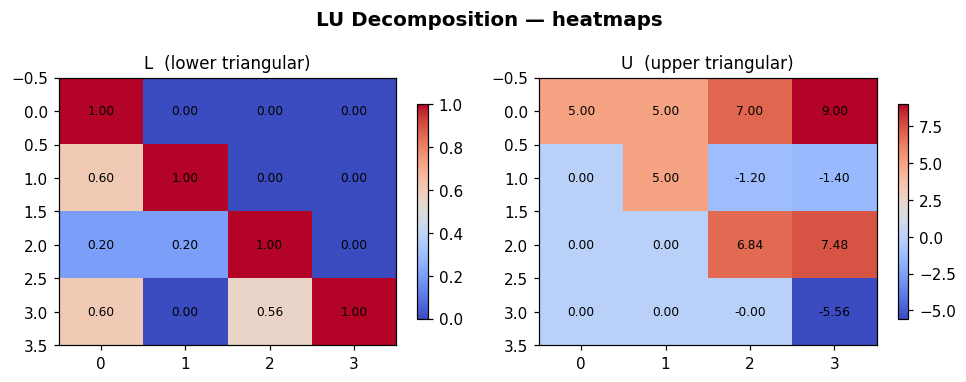

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, mat, title in zip(axes, [L, U], ["L  (lower triangular)", "U  (upper triangular)"]):
    im = ax.imshow(mat, cmap="coolwarm", aspect="auto")
    ax.set_title(title)
    plt.colorbar(im, ax=ax, shrink=0.8)
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            ax.text(j, i, f"{mat[i,j]:.2f}", ha="center", va="center", fontsize=8)
fig.suptitle("LU Decomposition — heatmaps", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

---
## Section 2 — Cholesky & QR Decomposition

In [5]:
from decompositions.cholesky import cholesky
from decompositions.qr import qr_decomposition

# ── Cholesky ──────────────────────────────────────────────────────────────────
rng2 = np.random.default_rng(2)
M    = rng2.normal(size=(5, 5))
A_pd = M.T @ M + np.eye(5)        # guaranteed positive-definite

L_chol = cholesky(A_pd)
chol_residual = np.linalg.norm(L_chol @ L_chol.T - A_pd)

print("── Cholesky ──")
print("L (lower triangular factor):")
print(np.round(L_chol, 6))
print(f"\nVerification  ‖L·Lᵀ − A‖ = {chol_residual:.2e}")

── Cholesky ──
L (lower triangular factor):
[[ 2.004594  0.        0.        0.        0.      ]
 [-0.334542  1.302455  0.        0.        0.      ]
 [ 0.411166 -0.050019  1.477808  0.        0.      ]
 [-0.290008  1.136388  1.16479   2.26268   0.      ]
 [-0.304639 -1.290161 -0.712659 -1.427631  1.50569 ]]

Verification  ‖L·Lᵀ − A‖ = 9.93e-16


In [6]:
# ── QR ────────────────────────────────────────────────────────────────────────
rng3  = np.random.default_rng(3)
A_qr  = rng3.normal(size=(6, 4))

Q, R = qr_decomposition(A_qr)

qr_residual  = np.linalg.norm(Q @ R - A_qr)
orth_residual = np.linalg.norm(Q.T @ Q - np.eye(Q.shape[1]))

print("── QR (Gram-Schmidt) ──")
print(f"Q shape: {Q.shape}   R shape: {R.shape}")
print(f"\nVerification  ‖Q·R − A‖ = {qr_residual:.2e}")
print(f"Orthogonality ‖Qᵀ·Q − I‖ = {orth_residual:.2e}")

── QR (Gram-Schmidt) ──
Q shape: (6, 4)   R shape: (4, 4)

Verification  ‖Q·R − A‖ = 3.28e-16
Orthogonality ‖Qᵀ·Q − I‖ = 7.54e-16


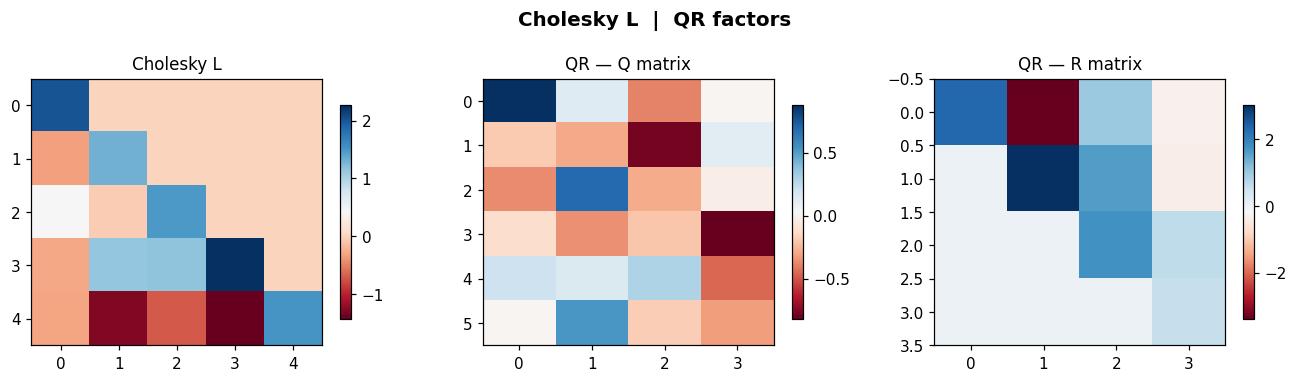

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
data = [(L_chol, "Cholesky L"), (Q, "QR — Q matrix"), (R, "QR — R matrix")]
for ax, (mat, title) in zip(axes, data):
    im = ax.imshow(mat, cmap="RdBu", aspect="auto")
    ax.set_title(title)
    plt.colorbar(im, ax=ax, shrink=0.8)
fig.suptitle("Cholesky L  |  QR factors", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

---
## Section 3 — Linear Solvers (Forward/Back Substitution + Conjugate Gradient)

In [8]:
from solvers.linear_solve import forward_substitution, backward_substitution
from solvers.conjugate_grad import conjugate_gradient

# ── Forward substitution  (lower-triangular system) ───────────────────────────
L_tri = np.array([[2., 0., 0.],
                  [1., 3., 0.],
                  [2.,-1., 1.]])
b_fwd = np.array([4., 7., 3.])

x_fwd = forward_substitution(L_tri, b_fwd)
print("── Forward substitution (L·x = b) ──")
print(f"x = {x_fwd}")
print(f"‖L·x − b‖ = {np.linalg.norm(L_tri @ x_fwd - b_fwd):.2e}\n")

# ── Backward substitution  (upper-triangular system) ──────────────────────────
U_tri = np.array([[2., 1., 1.],
                  [0., 3.,-1.],
                  [0., 0., 2.]])
b_bwd = np.array([4., 5., 2.])

x_bwd = backward_substitution(U_tri, b_bwd)
print("── Backward substitution (U·x = b) ──")
print(f"x = {x_bwd}")
print(f"‖U·x − b‖ = {np.linalg.norm(U_tri @ x_bwd - b_bwd):.2e}")

── Forward substitution (L·x = b) ──
x = [2.         1.66666667 0.66666667]
‖L·x − b‖ = 0.00e+00

── Backward substitution (U·x = b) ──
x = [0.5 2.  1. ]
‖U·x − b‖ = 0.00e+00


In [9]:
# ── Conjugate Gradient  (10×10 SPD system) ───────────────────────────────────
rng4 = np.random.default_rng(4)
M4   = rng4.normal(size=(10, 10))
A_spd = M4.T @ M4 + np.eye(10)    # symmetric positive-definite
b_cg  = np.arange(1., 11.)

x_cg = conjugate_gradient(A_spd, b_cg)
residual_cg = np.linalg.norm(A_spd @ x_cg - b_cg)
print(f"\nConjugate Gradient — residual ‖Ax − b‖ = {residual_cg:.2e}")
print(f"Solution x: {np.round(x_cg, 4)}")

Converged in 11 iterations.

Conjugate Gradient — residual ‖Ax − b‖ = 3.29e-14
Solution x: [1.4513 1.552  2.1575 6.4165 2.9347 0.5541 1.925  3.2456 3.7397 2.7235]


---
## Section 4 — Least Squares Regression

In [10]:
from solvers.least_squares import least_squares

rng5 = np.random.default_rng(5)
X_ls = np.linspace(0, 10, 60).reshape(-1, 1)
y_ls = 3.0 * X_ls[:, 0] + 2.0 + rng5.normal(scale=1.5, size=60)

result_ls = least_squares(X_ls, y_ls)

print("── Least Squares Fit  (y = 3x + 2 + noise) ──")
print(f"Learned intercept  : {result_ls['intercept']:.4f}  (true: 2.0)")
print(f"Learned coefficient: {result_ls['coefficients'][0]:.4f}  (true: 3.0)")
print(f"Train MSE          : {result_ls['mse']:.4f}")

── Least Squares Fit  (y = 3x + 2 + noise) ──
Learned intercept  : 1.4901  (true: 2.0)
Learned coefficient: 3.0375  (true: 3.0)
Train MSE          : 1.9907


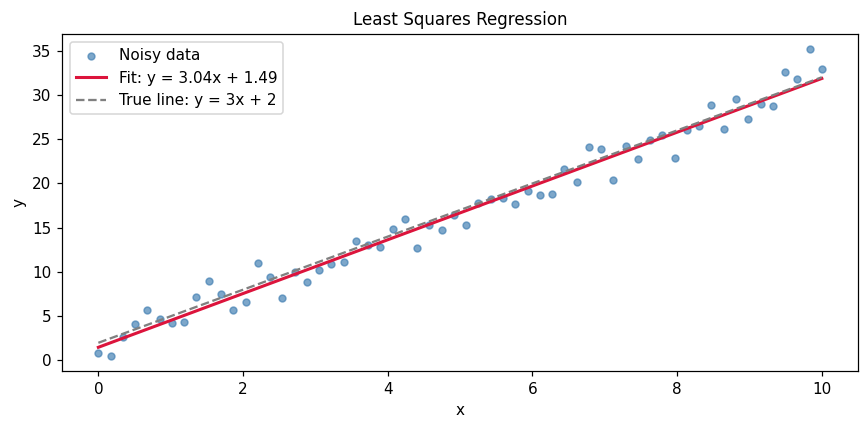

In [11]:
x_line = np.linspace(0, 10, 200)
y_line = result_ls["intercept"] + result_ls["coefficients"][0] * x_line

plt.figure(figsize=(8, 4))
plt.scatter(X_ls, y_ls, s=20, alpha=0.7, label="Noisy data", color="steelblue")
plt.plot(x_line, y_line, color="crimson", linewidth=2,
         label=f"Fit: y = {result_ls['coefficients'][0]:.2f}x + {result_ls['intercept']:.2f}")
plt.plot(x_line, 3 * x_line + 2, color="gray", linewidth=1.5, linestyle="--",
         label="True line: y = 3x + 2")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Least Squares Regression")
plt.legend()
plt.tight_layout()
plt.show()

---
## Section 5 — SVD Compression (Image Demo)

In [12]:
from spectral.svd import truncated_svd

# ── Load photo.jfif from the repository root ──────────────────────────────────
try:
    import cv2
    img_path = str(repo_root / "photo.jfif")
    img_bgr  = cv2.imread(img_path, cv2.IMREAD_COLOR)
    if img_bgr is None:
        raise FileNotFoundError
    img_rgb  = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    print(f"Image loaded: {img_rgb.shape}  (H × W × C)")
    USE_COLOR = True
except Exception:
    # Fallback: synthetic grayscale image so the notebook always runs
    print("photo.jfif not found — using synthetic 128×128 grayscale image.")
    rng_img  = np.random.default_rng(99)
    img_gray = (rng_img.normal(128, 40, (128, 128))).clip(0, 255).astype(np.uint8)
    USE_COLOR = False

Image loaded: (148, 265, 3)  (H × W × C)


In [13]:
def calculate_psnr(original, reconstructed):
    mse = np.mean((original.astype(float) - reconstructed.astype(float)) ** 2)
    return float("inf") if mse == 0 else 20 * np.log10(255.0 / np.sqrt(mse))

ranks = [5, 20, 50]
reconstructions = {}

for k in ranks:
    if USE_COLOR:
        channels = []
        for c in range(3):
            res = truncated_svd(img_rgb[:, :, c].astype(float), k)
            channels.append(res["A_approx"])
        recon = np.stack(channels, axis=2)
        orig  = img_rgb
    else:
        res   = truncated_svd(img_gray.astype(float), k)
        recon = res["A_approx"]
        orig  = img_gray

    recon_uint8 = np.clip(recon, 0, 255).astype(np.uint8)
    h, w        = orig.shape[:2]
    n_channels  = 3 if USE_COLOR else 1
    stored      = n_channels * k * (h + w + 1)
    total       = h * w * n_channels
    compression = (1 - stored / total) * 100
    psnr        = calculate_psnr(orig, recon_uint8)
    reconstructions[k] = recon_uint8
    print(f"Rank-{k:<3} | Compression: {compression:.1f}% | PSNR: {psnr:.1f} dB")

Rank-5   | Compression: 94.7% | PSNR: 20.2 dB
Rank-20  | Compression: 78.9% | PSNR: 24.7 dB
Rank-50  | Compression: 47.2% | PSNR: 30.1 dB


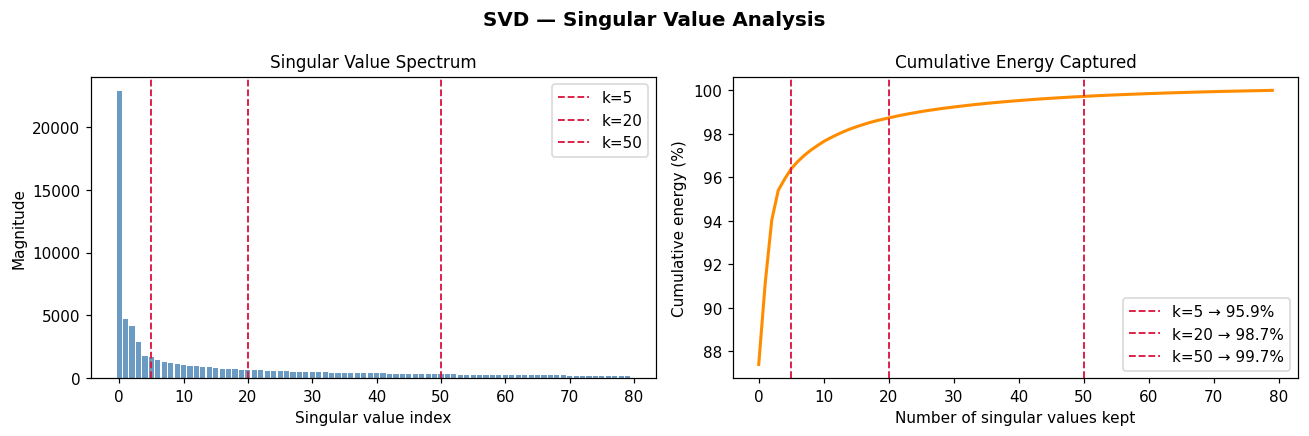

In [14]:
# ── Singular value spectrum ────────────────────────────────────────────────────
if USE_COLOR:
    channel_data = img_rgb[:, :, 0].astype(float)   # red channel
else:
    channel_data = img_gray.astype(float)

max_k = min(channel_data.shape)
sv_result = truncated_svd(channel_data, min(max_k, 80))
svs = sv_result["singular_values"]
energy = np.cumsum(svs**2) / np.sum(svs**2) * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(range(len(svs)), svs, color="steelblue", alpha=0.8)
for k in ranks:
    if k < len(svs):
        axes[0].axvline(k, color="crimson", linestyle="--", linewidth=1.2,
                        label=f"k={k}")
axes[0].set_xlabel("Singular value index")
axes[0].set_ylabel("Magnitude")
axes[0].set_title("Singular Value Spectrum")
axes[0].legend()

axes[1].plot(range(len(energy)), energy, color="darkorange", linewidth=2)
for k in ranks:
    if k < len(energy):
        axes[1].axvline(k, color="crimson", linestyle="--", linewidth=1.2,
                        label=f"k={k} → {energy[k-1]:.1f}%")
axes[1].set_xlabel("Number of singular values kept")
axes[1].set_ylabel("Cumulative energy (%)")
axes[1].set_title("Cumulative Energy Captured")
axes[1].legend()

plt.suptitle("SVD — Singular Value Analysis", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

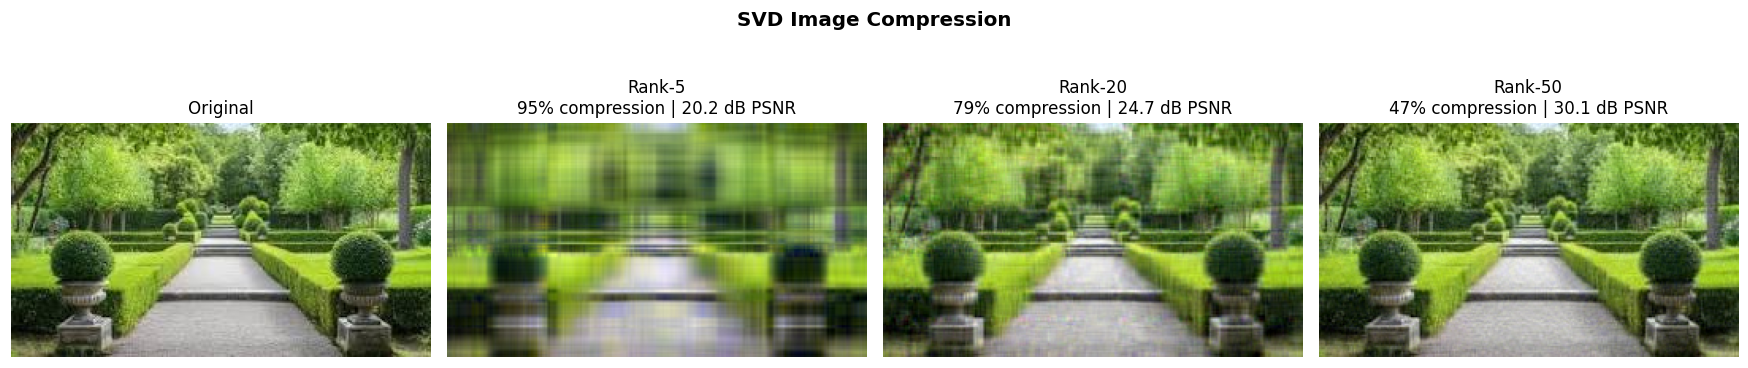

In [15]:
# ── Side-by-side reconstruction grid ──────────────────────────────────────────
cmap_arg = None if USE_COLOR else "gray"
orig_disp = img_rgb if USE_COLOR else img_gray

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(orig_disp, cmap=cmap_arg)
axes[0].set_title("Original")
axes[0].axis("off")

for ax, k in zip(axes[1:], ranks):
    h, w  = orig_disp.shape[:2]
    n_ch  = 3 if USE_COLOR else 1
    stored     = n_ch * k * (h + w + 1)
    total      = h * w * n_ch
    comp_pct   = (1 - stored / total) * 100
    psnr_val   = calculate_psnr(orig_disp, reconstructions[k])
    ax.imshow(reconstructions[k], cmap=cmap_arg)
    ax.set_title(f"Rank-{k}\n{comp_pct:.0f}% compression | {psnr_val:.1f} dB PSNR")
    ax.axis("off")

plt.suptitle("SVD Image Compression", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

---
## Section 6 — Gaussian Process Regression

In [16]:
# We replicate the GP internals here so we can display the plot inline
# (gp_regression.py uses the Agg backend for headless test saving)
from decompositions.cholesky import cholesky
from solvers.linear_solve import forward_substitution, backward_substitution

def rbf_kernel(X1, X2, sigma=1.0, length_scale=1.0):
    X1 = np.asarray(X1).reshape(-1, 1)
    X2 = np.asarray(X2).reshape(-1, 1)
    sq_dist = (X1 - X2.T) ** 2
    return (sigma ** 2) * np.exp(-sq_dist / (2 * length_scale ** 2))

def run_gp(n_samples=50, sigma=2.0, length_scale=1.0, sigma_n=1.0):
    """Returns (x, y, x_test, mean, variance, log_lik)."""
    np.random.seed(42)
    x = np.linspace(0, 2 * np.pi, n_samples)
    y = np.sin(x) + np.random.normal(0, 0.2, n_samples)

    K       = rbf_kernel(x, x, sigma=1.0, length_scale=1.0)
    K_noise = K + (sigma_n ** 2) * np.eye(n_samples)
    L       = cholesky(K_noise)
    z       = forward_substitution(L, y)
    alpha   = backward_substitution(L.T, z)

    log_lik = (
        -0.5 * np.dot(y, alpha)
        - np.sum(np.log(np.diag(L)))
        - 0.5 * n_samples * np.log(2 * np.pi)
    )

    x_test  = np.linspace(0, 2 * np.pi, 200)
    K_star  = rbf_kernel(x, x_test, sigma=sigma, length_scale=length_scale)
    mean    = K_star.T @ alpha

    V = np.column_stack([
        forward_substitution(L, K_star[:, j])
        for j in range(K_star.shape[1])
    ])

    K_test   = rbf_kernel(x_test, x_test, sigma=sigma, length_scale=length_scale)
    variance = np.maximum(np.diag(K_test) - np.sum(V ** 2, axis=0), 0.0)

    return x, y, x_test, mean, variance, log_lik

print("GP helpers defined ✓")

GP helpers defined ✓


Log marginal likelihood: -53.73


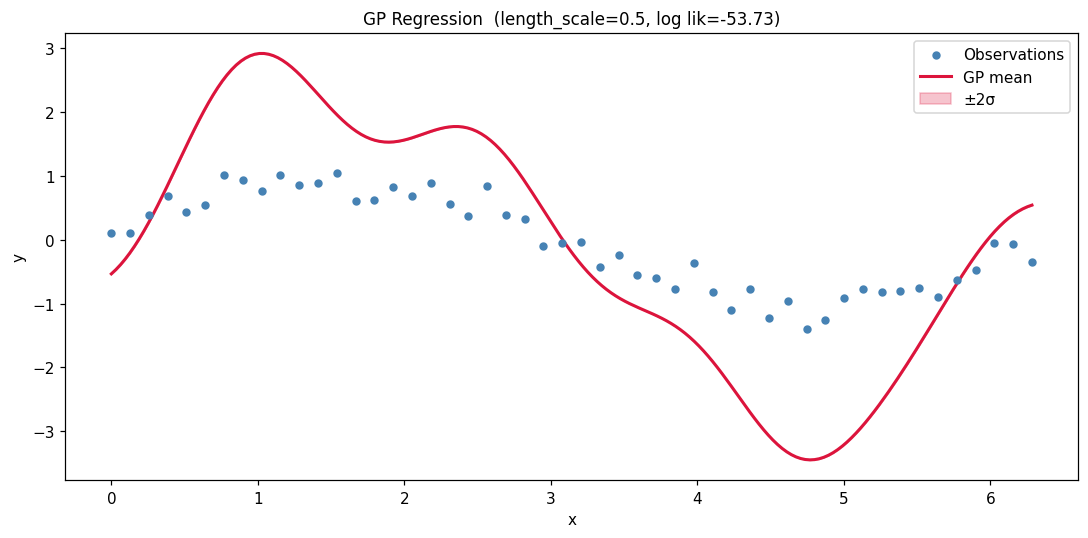

In [17]:
# ── Main GP run: n=50, sigma=2.0, length_scale=0.5, sigma_n=1.0 ──────────────
x, y, x_test, mean, variance, log_lik = run_gp(50, 2.0, 0.5, 1.0)
std = np.sqrt(variance)

print(f"Log marginal likelihood: {log_lik:.2f}")

plt.figure(figsize=(10, 5))
plt.scatter(x, y, s=20, color="steelblue", zorder=3, label="Observations")
plt.plot(x_test, mean, color="crimson", linewidth=2, label="GP mean")
plt.fill_between(x_test, mean - 2*std, mean + 2*std,
                 alpha=0.25, color="crimson", label="±2σ")
plt.xlabel("x")
plt.ylabel("y")
plt.title(f"GP Regression  (length_scale=0.5, log lik={log_lik:.2f})")
plt.legend()
plt.tight_layout()
plt.show()

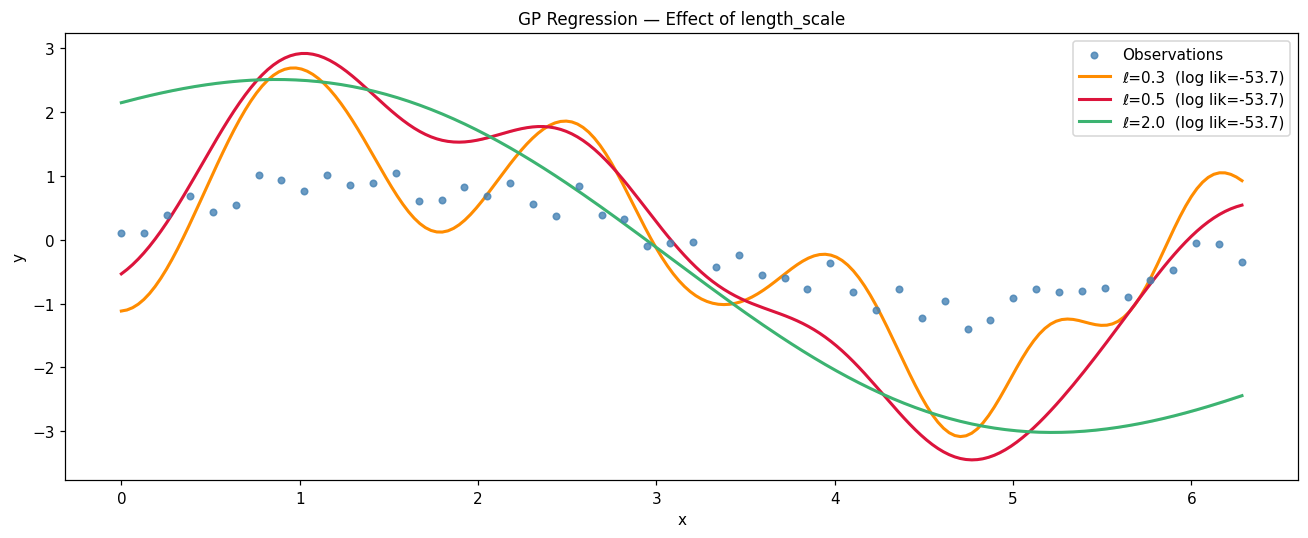

In [18]:
# ── Effect of length_scale: compare 0.3 vs 0.5 vs 2.0 ────────────────────────
length_scales = [0.3, 0.5, 2.0]
colors        = ["darkorange", "crimson", "mediumseagreen"]

plt.figure(figsize=(12, 5))
plt.scatter(x, y, s=18, color="steelblue", zorder=5, label="Observations", alpha=0.8)

for ls, col in zip(length_scales, colors):
    _, _, xt, mn, vr, ll = run_gp(50, 2.0, ls, 1.0)
    sd = np.sqrt(vr)
    plt.plot(xt, mn, color=col, linewidth=2,
             label=f"ℓ={ls}  (log lik={ll:.1f})")
    plt.fill_between(xt, mn - 2*sd, mn + 2*sd,
                     alpha=0.12, color=col)

plt.xlabel("x")
plt.ylabel("y")
plt.title("GP Regression — Effect of length_scale")
plt.legend()
plt.tight_layout()
plt.show()